In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import os
import json
import matplotlib.pyplot as plt

In [2]:
class MVTecDataset(Dataset):
    def __init__(self, samples, root_dir, transform=None):
        self.samples = samples
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_name = os.path.join(self.root_dir, self.samples[idx]['filepath'])
        image = Image.open(img_name).convert("RGB")
        label = self.samples[idx]['defect']['label']
        if self.transform:
            image = self.transform(image)
        return image, label

In [3]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

In [4]:
ROOT_DIR = "D:\\Projects\\Industrial Defect Detection\\dataset\\mvtec-ad"

with open(os.path.join(ROOT_DIR, "samples.json"), "r") as f:
    data = json.load(f)

samples = data['samples']

In [5]:
train_samples = [
    sample for sample in samples
    if sample["category"]["label"] == "metal_nut"
    and sample["defect"]["label"] == "good"
    and sample["split"] == "train"
]

test_samples = [
    sample for sample in samples
    if sample["category"]["label"] == "metal_nut"
    and sample["split"] == "test"
]

In [6]:
print("Training samples length: ", len(train_samples))
print("Testing samples length: ", len(test_samples))

Training samples length:  220
Testing samples length:  115


In [7]:
training_dataset = MVTecDataset(train_samples, ROOT_DIR, transform=transform)
testing_dataset = MVTecDataset(test_samples, ROOT_DIR, transform=transform)

In [8]:
print("Training data length: ", len(training_dataset))
print("Testing data length: ", len(testing_dataset))

image, label = training_dataset[0]

print("Image shape: ", image.shape)
print("Label: ", label)

Training data length:  220
Testing data length:  115
Image shape:  torch.Size([3, 128, 128])
Label:  good


In [9]:
from torch.utils.data import random_split, DataLoader

torch.manual_seed(42)

train_size = int(0.8 * len(training_dataset))
val_size = len(training_dataset) - train_size

train_dataset, val_dataset = random_split(
    training_dataset,
    [train_size, val_size]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    testing_dataset,
    batch_size=16,
    shuffle=False
)

In [10]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Number of labels:", len(labels))

Batch image shape: torch.Size([16, 3, 128, 128])
Number of labels: 16


In [11]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3, padding=1
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3, padding=1
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Identity()

        if in_channels != out_channels:
            self.shortcut = nn.Conv2d(
                in_channels, out_channels, 1
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        residual = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + residual

        return self.relu(out)
    

In [12]:
class Encoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.block1 = ResidualBlock(32, 32)

        self.down1 = nn.Sequential(
            nn.Conv2d(32, 64, 3, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.block2 = ResidualBlock(64, 64)

        self.down2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, 2, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        self.block3 = ResidualBlock(128, 128)

        self.down3 = nn.Sequential(
            nn.Conv2d(128, 256, 3, 2, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.fc_mu = nn.Linear(256 * 8 * 8, latent_dim)
        self.fc_log_var = nn.Linear(256 * 8 * 8, latent_dim)

    def forward(self, x):
        x = self.initial(x)
        x = self.block1(x)

        x = self.down1(x)
        x = self.block2(x)

        x = self.down2(x)
        x = self.block3(x)

        x = self.down3(x)

        x = torch.flatten(x, start_dim=1)

        mu = self.fc_mu(x)
        log_var = self.fc_log_var(x)

        return mu, log_var

In [13]:
class Decoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.fc = nn.Linear(latent_dim, 256 * 8 * 8)

        self.block0 = ResidualBlock(256, 256)

        self.up1 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            ResidualBlock(128, 128)
        )

        self.up2 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            ResidualBlock(64, 64)
        )

        self.up3 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            ResidualBlock(32, 32)
        )

        self.up4 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(32, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )

        self.output = nn.Sequential(
            nn.Conv2d(16, 3, 3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, z):
        z = self.fc(z)

        z = z.view(-1, 256, 8, 8)

        z = self.block0(z)

        z = self.up1(z)
        z = self.up2(z)
        z = self.up3(z)
        z = self.up4(z)

        return self.output(z)

In [14]:
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterize(mu, log_var)
        reconstructed = self.decoder(z)
        return reconstructed, mu, log_var
    
    def reconstruct(self, x):
        mu, log_var = self.encoder(x)
        reconstructed = self.decoder(mu)
        return reconstructed

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [32]:
def VAE_loss(reconstructed, x, mu, log_var, beta=0.1):

    recon_loss = nn.functional.l1_loss(
        reconstructed,
        x,
        reduction='sum'
    )

    kl_divergence = -0.5 * torch.sum(
        1 + log_var - mu.pow(2) - log_var.exp()
    )

    total_loss = recon_loss + beta * kl_divergence

    return total_loss

In [33]:
model = ConvVAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [34]:
for epoch in range(50):
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        reconstructed, mu, log_var = model(images)
        loss = VAE_loss(reconstructed, images, mu, log_var, beta=0.1)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f'Epoch {epoch+1}, Loss: {total_loss/len(train_loader.dataset):.4f}')

Epoch 1, Loss: 9865.8314
Epoch 2, Loss: 4225.5217
Epoch 3, Loss: 2679.5908
Epoch 4, Loss: 2315.3092
Epoch 5, Loss: 2069.1261
Epoch 6, Loss: 1925.1812
Epoch 7, Loss: 1859.9067
Epoch 8, Loss: 1832.8896
Epoch 9, Loss: 1764.2686
Epoch 10, Loss: 1718.3440
Epoch 11, Loss: 1729.5655
Epoch 12, Loss: 1672.6106
Epoch 13, Loss: 1609.5049
Epoch 14, Loss: 1549.3104
Epoch 15, Loss: 1621.4025
Epoch 16, Loss: 1575.5530
Epoch 17, Loss: 1542.9761
Epoch 18, Loss: 1506.1125
Epoch 19, Loss: 1501.8745
Epoch 20, Loss: 1477.0524
Epoch 21, Loss: 1427.9166
Epoch 22, Loss: 1405.4343
Epoch 23, Loss: 1417.1376
Epoch 24, Loss: 1410.4283
Epoch 25, Loss: 1430.8563
Epoch 26, Loss: 1384.1655
Epoch 27, Loss: 1365.9215
Epoch 28, Loss: 1378.3286
Epoch 29, Loss: 1394.9130
Epoch 30, Loss: 1380.1656
Epoch 31, Loss: 1326.0122
Epoch 32, Loss: 1323.0112
Epoch 33, Loss: 1313.1879
Epoch 34, Loss: 1327.4725
Epoch 35, Loss: 1270.7115
Epoch 36, Loss: 1259.6509
Epoch 37, Loss: 1241.4746
Epoch 38, Loss: 1216.0716
Epoch 39, Loss: 1248.

In [35]:
model.eval()

all_errors = []
all_labels = []
all_originals = []
all_reconstructed = []

test_loss = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        reconstructed, mu, log_var = model(images)

        loss = VAE_loss(reconstructed, images, mu, log_var)
        test_loss += loss.item()

        errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        all_errors.extend(errors.cpu().numpy())
        all_labels.extend(labels)
        all_originals.extend(images.cpu())
        all_reconstructed.extend(reconstructed.cpu())

print(f"Test Loss: {test_loss / len(test_loader.dataset):.4f}")

Test Loss: 1697.9605


In [36]:
def show_reconstruction(index):
    original = all_originals[index].permute(1, 2, 0)
    reconstructed = all_reconstructed[index].permute(1, 2, 0)

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(reconstructed)
    plt.title("Reconstructed Image")
    plt.axis("off")

    plt.show()

    print("Label:", all_labels[index])
    print("Reconstruction Error:", all_errors[index])

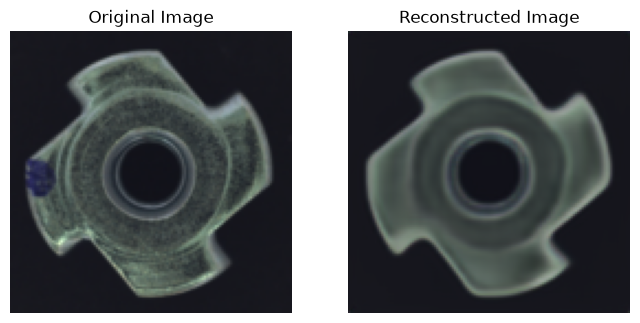

Label: color
Reconstruction Error: 0.0023322557


In [37]:
show_reconstruction(0)

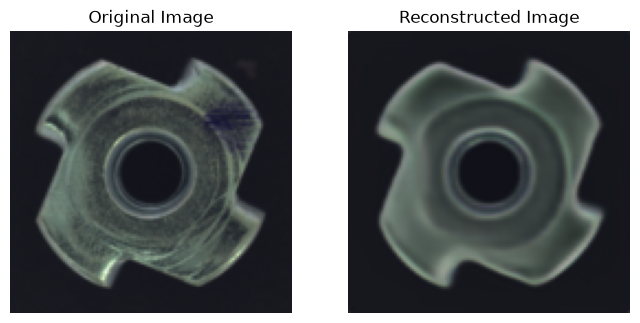

Label: color
Reconstruction Error: 0.0021658489


In [38]:
show_reconstruction(1)

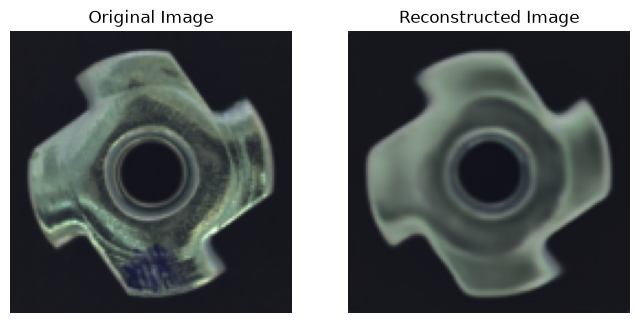

Label: color
Reconstruction Error: 0.003774271


In [39]:
show_reconstruction(2)

In [40]:
normal_errors = [
    error for error, label in zip(all_errors, all_labels)
    if label == "good"
]

defective_errors = [
    error for error, label in zip(all_errors, all_labels)
    if label != "good"
]

print("Average Normal Error:", sum(normal_errors) / len(normal_errors))
print("Average Defective Error:", sum(defective_errors) / len(defective_errors))

Average Normal Error: 0.0026572722
Average Defective Error: 0.0042625545


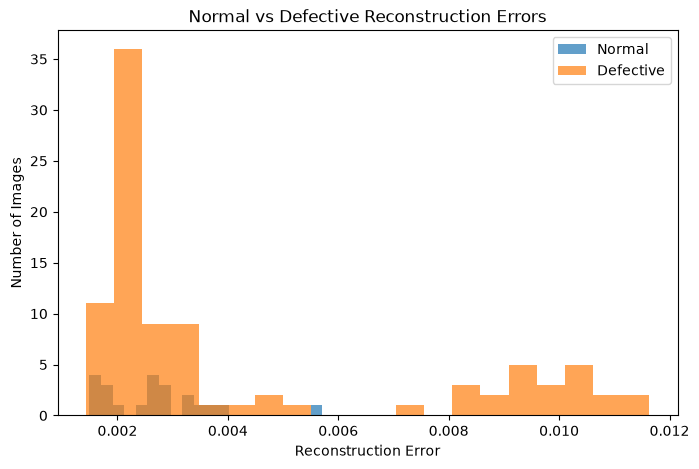

In [41]:
plt.figure(figsize=(8, 5))

plt.hist(normal_errors, bins=20, alpha=0.7, label="Normal")
plt.hist(defective_errors, bins=20, alpha=0.7, label="Defective")

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Normal vs Defective Reconstruction Errors")
plt.legend()
plt.show()

In [42]:
import numpy as np

errors = []

model.eval()

with torch.no_grad():
    for batch in val_loader:

        # Handles datasets returning either images or (images, labels)
        images = batch[0] if isinstance(batch, (tuple, list)) else batch

        images = images.to(device)

        reconstructed = model.reconstruct(images)

        batch_errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        errors.extend(batch_errors.cpu().numpy())

In [43]:
threshold = np.percentile(errors, 95)

print("Validation images:", len(errors))
print("Mean reconstruction error:", np.mean(errors))
print("95th percentile threshold:", threshold)

Validation images: 44
Mean reconstruction error: 0.0019439642
95th percentile threshold: 0.002916485


In [44]:
batch = next(iter(test_loader))

print("Batch type:", type(batch))
print("Images shape:", batch[0].shape)
print("Labels:", batch[1])

Batch type: <class 'list'>
Images shape: torch.Size([16, 3, 128, 128])
Labels: ('color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color', 'color')


In [45]:
unique_labels = set(testing_dataset[i][1] for i in range(len(testing_dataset)))

print("Unique labels:", unique_labels)

Unique labels: {'flip', 'color', 'bent', 'scratch', 'good'}


In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

y_true = []
y_pred = []
y_scores = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        reconstructed = model.reconstruct(images)

        errors = torch.mean(
            (images - reconstructed) ** 2,
            dim=(1, 2, 3)
        )

        predictions = (errors > threshold).int()

        # Convert string labels into binary labels
        actual = [0 if label == "good" else 1 for label in labels]

        y_true.extend(actual)
        y_pred.extend(predictions.cpu().numpy())
        y_scores.extend(errors.cpu().numpy())

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Normal", "Defective"]
))

print("ROC-AUC:", roc_auc_score(y_true, y_scores))

Accuracy: 0.4608695652173913
Precision: 0.8604651162790697
Recall: 0.3978494623655914
F1 Score: 0.5441176470588235

Confusion Matrix:
[[16  6]
 [56 37]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.22      0.73      0.34        22
   Defective       0.86      0.40      0.54        93

    accuracy                           0.46       115
   macro avg       0.54      0.56      0.44       115
weighted avg       0.74      0.46      0.51       115

ROC-AUC: 0.5928641251221897


Normal mean: 0.002653555
Defective mean: 0.004254142
Normal min/max: 0.0014527901 0.005779965
Defective min/max: 0.0013983756 0.011528219


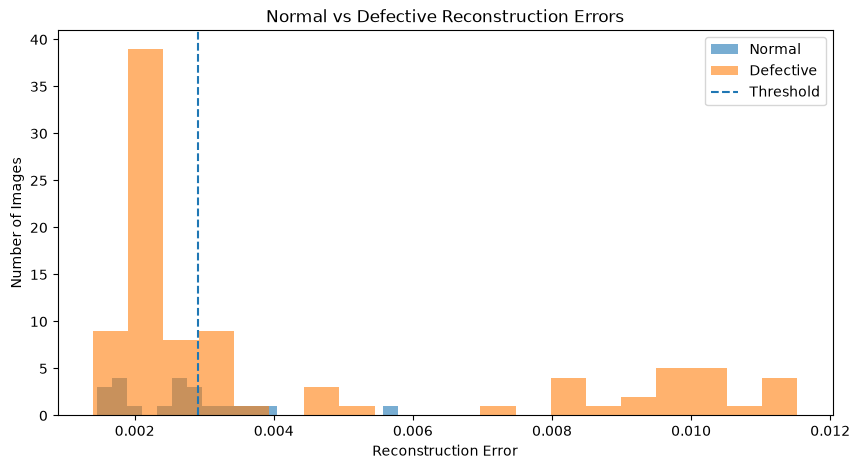

In [47]:
import matplotlib.pyplot as plt
import numpy as np

normal_errors = [
    error for error, label in zip(y_scores, y_true)
    if label == 0
]

defective_errors = [
    error for error, label in zip(y_scores, y_true)
    if label == 1
]

print("Normal mean:", np.mean(normal_errors))
print("Defective mean:", np.mean(defective_errors))

print("Normal min/max:",
      np.min(normal_errors), np.max(normal_errors))

print("Defective min/max:",
      np.min(defective_errors), np.max(defective_errors))

plt.figure(figsize=(10, 5))

plt.hist(normal_errors, bins=20, alpha=0.6, label="Normal")
plt.hist(defective_errors, bins=20, alpha=0.6, label="Defective")

plt.axvline(threshold, linestyle="--", label="Threshold")

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Normal vs Defective Reconstruction Errors")
plt.legend()
plt.show()